In [ ]:
import os
import random
import warnings
warnings.filterwarnings("ignore", message=".*tpfmodel submodule.*")

import lightkurve as lk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astroquery.mast import Catalogs

LOG_FILE = "scanned_stars_log.csv"
BATCH_SIZE = 20

# =====================================================================
# DISCOVERY ENGINE TARGETING SETTINGS
# - "RANDOM_FIELD": Picks a random multi-sector TESS field so every user
#                   explores a fresh region of the sky
# - "MANUAL":       Uses MANUAL_CENTER below if you want a specific star.
# - SHUFFLE_TARGETS: If True, randomizes the order of unscanned stars so two
#                    people running the repo simultaneously never scan the same batch
# =====================================================================
SEARCH_MODE = "RANDOM_FIELD"   # Options: "RANDOM_FIELD" or "MANUAL"
MANUAL_CENTER = "TOI-700"      # Only used if SEARCH_MODE == "MANUAL"
SEARCH_RADIUS_DEG = 5.0
SHUFFLE_TARGETS = True         # True = random unscanned stars; False = brightest first

# Curated pool of 12 high-yield, multi-sector TESS fields (away from Galactic Plane crowding)
PRIME_TESS_FIELDS = [
    ("TOI-700",   "Southern Continuous Viewing Zone (Dorado)"),
    ("L 98-59",   "Southern Deep Multi-Sector Field (Volans)"),
    ("LHS 1140",  "Clean High-Latitude Southern Field (Cetus)"),
    ("LHS 3844",  "Southern Multi-Sector Field (Indus)"),
    ("TOI-270",   "Southern Deep Field (Pictor)"),
    ("GJ 357",    "Sub-Neptune / Rocky Zone (Hydra)"),
    ("LP 791-18", "Southern Temperate Red Dwarf Field (Crater)"),
    ("TOI-1452",  "Northern Continuous Viewing Zone (Draco)"),
    ("K2-18",     "High-Galactic-Latitude Field (Leo)"),
    ("GJ 1214",   "Northern Equatorial Deep Field (Ophiuchus)"),
    ("LHS 1815",  "Southern Deep Field (Pictor South)"),
    ("GJ 486",    "High-Latitude Northern Field (Virgo)")
]

if SEARCH_MODE == "RANDOM_FIELD":
    SEARCH_CENTER, FIELD_DESC = random.choice(PRIME_TESS_FIELDS)
else:
    SEARCH_CENTER, FIELD_DESC = MANUAL_CENTER, "Custom User-Selected Field"

# Load NASA's master list of known TESS Objects of Interest (TOIs)
toi_url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+tid,toi,tfopwg_disp+from+toi&format=csv"
toi_df = pd.read_csv(toi_url)
known_toi_ids = set(toi_df["tid"].dropna().astype(int))
print(f"Loaded {len(known_toi_ids)} unique stars with known NASA TOI signals.")

# Load the shared persistent log of stars ALREADY scanned in past runs
if os.path.exists(LOG_FILE):
    log_df = pd.read_csv(LOG_FILE)
    already_scanned_ids = set(
        log_df["TIC ID"].dropna().astype(str).str.replace("TIC ", "", regex=False).astype(int)
    )
    print(f"Loaded '{LOG_FILE}': Excluding {len(already_scanned_ids)} previously scanned stars.")
else:
    already_scanned_ids = set()
    print("No existing scan log found — 'scanned_stars_log.csv' will be created automatically.")

# Server-Side Filtered Query around the selected TESS field
print(f"\nSelected Sky Region: {SEARCH_CENTER} — {FIELD_DESC} (radius={SEARCH_RADIUS_DEG}°)")
print("Querying MAST TIC with server-side filters...")
raw_stars = Catalogs.query_criteria(
    objectname=SEARCH_CENTER,
    radius=SEARCH_RADIUS_DEG,
    catalog="TIC",
    lumclass="DWARF",
    Teff=[2500, 4000],
    rad=[0.1, 0.5],
    Tmag=[6.0, 14.2]
).to_pandas()

raw_stars["ID_int"] = raw_stars["ID"].astype(int)

# Exclude NASA TOIs AND any star already in scanned_stars_log.csv
excluded_ids = known_toi_ids.union(already_scanned_ids)
unanalyzed_dwarfs = (
    raw_stars[~raw_stars["ID_int"].isin(excluded_ids)]
    .dropna(subset=["Teff", "rad", "mass", "Jmag"])
)

# Shuffle or Sort the Target Queue
if SHUFFLE_TARGETS and len(unanalyzed_dwarfs) > 0:
    # Randomize the queue so every user/session scans a unique set of stars
    unanalyzed_dwarfs = unanalyzed_dwarfs.sample(frac=1.0).reset_index(drop=True)
    order_msg = "randomly shuffled for unique discovery"
else:
    unanalyzed_dwarfs = unanalyzed_dwarfs.sort_values("Tmag").reset_index(drop=True)
    order_msg = "sorted brightest-first"

print(f"Ready {len(unanalyzed_dwarfs)} unscanned Red Dwarfs queued up ({order_msg}).")
unanalyzed_dwarfs[["ID", "Tmag", "Teff", "rad", "mass", "Jmag"]].head(10)

Loaded 7826 unique stars with known NASA TOI signals.
No existing scan log found — 'scanned_stars_log.csv' will be created automatically when Cell 3 runs.
Querying MAST TIC around TOI-700 (radius=5.0 deg)...
Ready! 311 unscanned Red Dwarfs queued up.


,ID,Tmag,Teff,rad,mass,Jmag
0,176954932,10.4291,3349.0,0.371650,0.359165,8.853
1,167308252,10.6828,3423.0,0.371077,0.358508,9.226
2,167422188,10.8579,3708.0,0.494944,0.493036,9.550
3,374943202,11.0210,3782.0,0.442164,0.438131,9.779
4,176955267,11.3577,3247.0,0.311188,0.289422,9.699
5,167338863,11.3579,3473.0,0.447029,0.443370,9.869
6,167417695,11.4953,3533.0,0.416904,0.410427,10.089
7,177236338,11.5497,3410.0,0.439100,0.434814,10.001
8,176981169,11.6076,3577.0,0.360655,0.346509,10.252
9,176933645,11.6308,3615.0,0.494395,0.492489,10.299


In [34]:
def scan_star_for_transits(star_row, max_sectors=3):
    """
    Stitches up to 3 contiguous TESS sectors, runs BLS on a fixed 10,000-point grid,
    and applies 6 automated vetting guardrails.
    """
    tic_id = f"TIC {int(star_row['ID'])}"
    R_star = float(star_row["rad"])
    M_star = float(star_row["mass"])
    T_star = float(star_row["Teff"])
    J_mag  = float(star_row["Jmag"])
    
    # Search MAST: Prefer 2-min SPOC, fallback to TESS-SPOC or QLP Full-Frame light curves
    search = lk.search_lightcurve(tic_id, mission="TESS", author="SPOC", exptime=120)
    if len(search) == 0:
        search = lk.search_lightcurve(tic_id, mission="TESS", author="TESS-SPOC")
    if len(search) == 0:
        search = lk.search_lightcurve(tic_id, mission="TESS", author="QLP")
    if len(search) == 0:
        print(f"  -> No TESS light curve product found on MAST for {tic_id}")
        return None, None, None
    
    # Pick up to 'max_sectors' from the latest CONTIGUOUS observing season (<120 days apart)
    latest_idx = len(search) - 1
    lc_list = [search[latest_idx].download()]
    latest_start = float(lc_list[0].time.value.min())
    
    for idx in range(latest_idx - 1, -1, -1):
        if len(lc_list) >= max_sectors:
            break
        candidate_lc = search[idx].download()
        cand_end = float(candidate_lc.time.value.max())
        if (latest_start - cand_end) <= 120.0:
            lc_list.insert(0, candidate_lc)
            latest_start = float(candidate_lc.time.value.min())
        else:
            break
            
    n_sec = len(lc_list)
    lc_flat = (
        lk.LightCurveCollection(lc_list)
        .stitch()
        .remove_nans()
        .flatten(window_length=401)
        .remove_outliers(sigma_lower=10.0, sigma_upper=3.0)
    )
    
    # Run BLS on a strict 10,000-point period grid (1.1 to 11.5 days)
    period_grid = np.linspace(1.1, 11.5, 10000)
    duration_grid = np.linspace(0.04, 0.15, 10)
    bls = lc_flat.to_periodogram(method="bls", period=period_grid, duration=duration_grid)
    
    period = float(bls.period_at_max_power.value)
    t0 = float(bls.transit_time_at_max_power.value)
    duration = float(bls.duration_at_max_power.value)
    depth = float(bls.depth_at_max_power.value)
    
    # Detrend BLS power spectrum to compute clean SDE
    power_vals = np.asarray(bls.power.value, dtype=float)
    rolling_med = pd.Series(power_vals).rolling(500, center=True, min_periods=1).median().to_numpy()
    detrended_power = power_vals - rolling_med
    sde = float(detrended_power.max() / np.nanstd(detrended_power))
    
    # Extract time & flux arrays for physical vetting tests
    t_arr = np.asarray(lc_flat.time.value, dtype=float)
    f_arr = np.asarray(lc_flat.flux.value, dtype=float)
    
    phase_days = (t_arr - t0 + 0.5 * period) % period - 0.5 * period
    in_transit = np.abs(phase_days) <= (0.5 * duration)
    out_of_transit = np.abs(phase_days) > duration
    
    n_points_in_transit = int(np.sum(in_transit))
    orbit_nums_all = np.round((t_arr - t0) / period).astype(int)
    unique_orbits = np.unique(orbit_nums_all[in_transit])
    n_distinct_transits = int(len(unique_orbits))
    
    median_dip_depth = float(1.0 - np.nanmedian(f_arr[in_transit])) if n_points_in_transit > 0 else 0.0
    
    # Flat Baseline vs. Rotational Wave / Noisy Flat-Liner Check
    oot_phases = phase_days[out_of_transit]
    oot_fluxes = f_arr[out_of_transit]
    bins = np.linspace(-0.5 * period, 0.5 * period, 51)
    bin_indices = np.digitize(oot_phases, bins)
    binned_oot = [np.nanmedian(oot_fluxes[bin_indices == b]) for b in range(1, 51) if np.sum(bin_indices == b) >= 5]
    oot_wave_std = float(np.nanstd(binned_oot)) if len(binned_oot) > 5 else 1e-3
    dip_to_wave_ratio = float(median_dip_depth / max(oot_wave_std, 1e-6))
    
    # Per-Transit Pass Consistency (Do >=75% of individual orbits actually dip?)
    valid_passes = 0
    dipped_passes = 0
    for orb in unique_orbits:
        orb_mask = in_transit & (orbit_nums_all == orb)
        if np.sum(orb_mask) >= 3:
            valid_passes += 1
            if (1.0 - np.nanmedian(f_arr[orb_mask])) > (0.35 * depth):
                dipped_passes += 1
    pass_consistency_pct = float((dipped_passes / max(valid_passes, 1)) * 100.0)
    
    # Odd vs. Even Transit Depth Check
    double_p = period * 2.0
    odd_in = np.abs((t_arr - t0 + 0.5 * double_p) % double_p - 0.5 * double_p) <= (0.5 * duration)
    even_in = np.abs((t_arr - (t0 + period) + 0.5 * double_p) % double_p - 0.5 * double_p) <= (0.5 * duration)
    odd_depth = float(1.0 - np.nanmedian(f_arr[odd_in])) if np.any(odd_in) else depth
    even_depth = float(1.0 - np.nanmedian(f_arr[even_in])) if np.any(even_in) else depth
    odd_even_diff_pct = float(abs(odd_depth - even_depth) / max(abs(odd_depth), abs(even_depth), 1e-6) * 100.0)
    
    # Calculate Planet Properties & JWST TSM Score
    r_earth = float(R_star * np.sqrt(max(depth, 0.0)) * 109.076)
    a_au = float((M_star * (period / 365.25) ** 2) ** (1 / 3))
    t_eq = float(T_star * np.sqrt(R_star / (2 * a_au * 215.032)) * ((1 - 0.3) ** 0.25))
    
    m_earth = r_earth ** 2.06 if r_earth < 1.23 else 1.436 * (r_earth ** 1.7)
    scale_fac = 0.190 if r_earth < 1.5 else 1.26
    tsm = float(scale_fac * ((r_earth ** 3) * t_eq / (m_earth * (R_star ** 2))) * (10 ** (-J_mag / 5)))
    
    # Automated Vetting Verdict Waterfall
    if n_distinct_transits < 3 or n_points_in_transit < 15 or median_dip_depth <= 0.0002:
        vet_status = f"Reject: Gap Glitch ({n_distinct_transits} transits)"
    elif r_earth >= 8.0:
        vet_status = "Reject: Too Large (EB)"
    elif dip_to_wave_ratio < 2.5:
        vet_status = f"Reject: Wavy/Noisy Baseline (SNR={dip_to_wave_ratio:.1f})"
    elif pass_consistency_pct < 75.0:
        vet_status = f"Reject: Inconsistent Passes ({dipped_passes}/{valid_passes})"
    elif odd_even_diff_pct > 50.0:
        vet_status = "Reject: Odd/Even Asymmetry"
    elif sde >= 6.5:
        vet_status = "PASS: Coherent Candidate"
    else:
        vet_status = "Weak / Noise Floor"
        
    result = {
        "TIC ID": tic_id,
        "Sectors": int(n_sec),
        "SDE (Signal Strength)": round(sde, 2),
        "Period (d)": round(period, 4),
        "Transits": f"{dipped_passes}/{valid_passes}",
        "Dip SNR": round(dip_to_wave_ratio, 2),
        "Est. Radius (R_earth)": round(r_earth, 2),
        "Odd/Even Diff (%)": round(odd_even_diff_pct, 1),
        "JWST TSM": round(tsm, 1),
        "Vetting Verdict": vet_status
    }
    return result, lc_flat, bls

In [ ]:
# =====================================================================
# FULLY AUTOMATED, PERSISTENT BATCH SCANNER
# Every time you run this cell, it scans the next 20 unscanned stars,
# saves their results to 'scanned_stars_log.csv', and removes them from the queue
# =====================================================================
if len(unanalyzed_dwarfs) == 0:
    print("All stars in this region have been scanned and logged")
    print("To explore a new patch of sky, change SEARCH_CENTER in Cell 1 (e.g., 'L 98-59' or 'LHS 1140').")
else:
    target_batch = unanalyzed_dwarfs.head(BATCH_SIZE).copy()
    print(f"Scanning next {len(target_batch)} unscanned stars ({len(unanalyzed_dwarfs)} remaining in queue)...")
    
    results = []
    high_sde_candidates = {}
    scanned_this_run = []
    
    for idx, (_, star_row) in enumerate(target_batch.iterrows(), 1):
        tic_name = f"TIC {int(star_row['ID'])}"
        print(f"[{idx}/{len(target_batch)}] Scanning {tic_name} (Tmag={star_row['Tmag']:.2f}, Teff={star_row['Teff']:.0f}K)...")
        
        try:
            res, lc_flat, bls = scan_star_for_transits(star_row, max_sectors=3)
            if res is not None:
                results.append(res)
                scanned_this_run.append(res)
                if res["SDE (Signal Strength)"] >= 6.4:
                    high_sde_candidates[tic_name] = (res, lc_flat, bls)
            else:
                scanned_this_run.append({"TIC ID": tic_name, "Vetting Verdict": "No TESS Light Curve"})
        except Exception as e:
            print(f"  -> Skipped {tic_name}: {e}")
            scanned_this_run.append({"TIC ID": tic_name, "Vetting Verdict": f"Error: {str(e)[:40]}"})
            
    # Permanently append this batch to 'scanned_stars_log.csv' on disk
    batch_log_df = pd.DataFrame(scanned_this_run)
    if os.path.exists(LOG_FILE):
        existing_log = pd.read_csv(LOG_FILE)
        combined_log = pd.concat([existing_log, batch_log_df], ignore_index=True).drop_duplicates(subset=["TIC ID"], keep="last")
        combined_log.to_csv(LOG_FILE, index=False)
    else:
        batch_log_df.to_csv(LOG_FILE, index=False)
        
    # Remove the batch we just scanned from the active queue in memory
    unanalyzed_dwarfs = unanalyzed_dwarfs.iloc[len(target_batch):].reset_index(drop=True)
    print(f"\nBatch logged to '{LOG_FILE}' {len(unanalyzed_dwarfs)} unscanned stars remaining in queue.")
    
    # Display the ranked multi-sector leaderboard (PASS candidates first, then sorted by SDE)
    if len(results) > 0:
        leaderboard = pd.DataFrame(results)
        leaderboard["_pass_sort"] = leaderboard["Vetting Verdict"].str.startswith("PASS")
        leaderboard = (
            leaderboard.sort_values(["_pass_sort", "SDE (Signal Strength)"], ascending=[False, False])
            .drop(columns=["_pass_sort"])
            .reset_index(drop=True)
        )
        display(leaderboard)
        print(f"Saved {len(high_sde_candidates)} signals with SDE >= 6.4 for visual plotting in Cell 4.")
    else:
        print("No valid light curves returned in this batch.")

Scanning next 20 unscanned stars (311 remaining in queue)...
[1/20] Scanning TIC 176954932 (Tmag=10.43, Teff=3349K)...
[2/20] Scanning TIC 167308252 (Tmag=10.68, Teff=3423K)...
[3/20] Scanning TIC 167422188 (Tmag=10.86, Teff=3708K)...
[4/20] Scanning TIC 374943202 (Tmag=11.02, Teff=3782K)...
[5/20] Scanning TIC 176955267 (Tmag=11.36, Teff=3247K)...
[6/20] Scanning TIC 167338863 (Tmag=11.36, Teff=3473K)...
[7/20] Scanning TIC 167417695 (Tmag=11.50, Teff=3533K)...
[8/20] Scanning TIC 177236338 (Tmag=11.55, Teff=3410K)...
[9/20] Scanning TIC 176981169 (Tmag=11.61, Teff=3577K)...
[10/20] Scanning TIC 176933645 (Tmag=11.63, Teff=3615K)...
[11/20] Scanning TIC 167721744 (Tmag=11.75, Teff=3455K)...
[12/20] Scanning TIC 166970183 (Tmag=11.85, Teff=3468K)...
[13/20] Scanning TIC 150300935 (Tmag=12.14, Teff=3214K)...
  -> Skipped TIC 150300935: Download of mast:TESS/product/tess2025232030459-s0096-0000000150300935-0293-s_lc.fits failed. MAST returns ERROR: HTTPError: 500 Server Error: Internal S

,TIC ID,Sectors,SDE (Signal Strength),Period (d),Transits,Dip SNR,Est. Radius (R_earth),Odd/Even Diff (%),JWST TSM,Vetting Verdict
0,TIC 150250057,3,8.50,8.9351,8/9,11.98,1.98,2.4,25.0,PASS: Coherent Candidate
1,TIC 176954932,3,8.38,11.2379,5/5,12.97,1.08,42.8,8.6,PASS: Coherent Candidate
2,TIC 150438041,3,7.28,2.4251,22/28,2.97,1.12,25.8,4.4,PASS: Coherent Candidate
3,TIC 166970183,3,7.19,5.1314,12/12,6.00,1.01,2.8,5.2,PASS: Coherent Candidate
4,TIC 150064737,1,7.05,3.7221,9/12,3.79,1.71,20.3,27.6,PASS: Coherent Candidate
5,TIC 177236338,3,6.60,9.0194,6/8,8.01,1.20,38.6,4.6,PASS: Coherent Candidate
6,TIC 167308252,3,10.15,1.1510,36/54,1.14,0.46,66.5,7.1,Reject: Gap Glitch (54 transits)
7,TIC 167338863,3,7.59,5.4684,8/11,5.58,1.14,37.4,5.4,Reject: Inconsistent Passes (8/11)
8,TIC 167422188,3,7.46,2.6196,22/36,4.02,0.80,21.3,5.2,Reject: Inconsistent Passes (22/36)
9,TIC 167417695,3,7.05,2.7818,23/35,2.58,0.83,38.6,5.2,Reject: Inconsistent Passes (23/35)


Saved 14 signals with SDE >= 6.4 for visual plotting in Cell 4.


## Part 1: 3-Panel Diagnostic Vetting Cheat Sheet (Cell 4)

Use these three 5-second visual rules to evaluate each candidate's **BLS Periodogram**, **Phase-Folded Dip**, and **Odd vs. Even Transit Check**:

| Panel | Rule Name | ✅ Real Planet Candidate | ❌ False Alarm / Noise |
| :--- | :--- | :--- | :--- |
| **1. Left Plot**<br>*(BLS Periodogram)* | **The "Skyscraper vs. Tall Grass" Rule** | A sharp needle inside the gold highlight bar that stands **at least 2x taller** than the surrounding background spikes. | **Tall Grass:** Dozens of random navy spikes across the chart are almost as tall as the peak inside the gold bar. |
| **2. Middle Plot**<br>*(Phase-Folded Dip)* | **The "Bowl vs. Ruler" Rule** | The crimson binned line sits flat along `1.000` on the left and right shoulders, dropping into a **distinct, localized U-shaped bowl** at `Phase = 0.0`. | **Flat Ruler or Sine Wave:** The crimson line looks flat across `0.0`, or curves continuously like a wide roller-coaster wave across the entire window. |
| **3. Right Plot**<br>*(Odd vs. Even Check)* | **The "Blue & Orange Shadow" Rule** | The solid blue line (**Odd Transits**) and dashed orange line (**Even Transits**) trace the **exact same U-shaped valley together** like shadows. | **Out-of-Sync or Asymmetric:** One line bumps upward while the other drops, or one color is more than $50\%$ deeper than the other. |

> **Watch Out for Auto-Zoom on the Right Plot:** Matplotlib automatically zooms the Y-axis of the right-hand plot to fit the binned lines. Always check the Y-axis numbers (`0.9995` vs `0.9950`) and verify that the dip is genuinely visible in the middle plot first

![3-Panel Vetting Guide](ref_3panel_guide.png)


[1/14] === TIC 150250057 | PASS: Coherent Candidate ===
SDE: 8.5 | Period: 8.9351 d | Passes Dipped: 8/9 | Dip SNR: 11.98 | Radius: 1.98 R_earth | TSM: 25.0


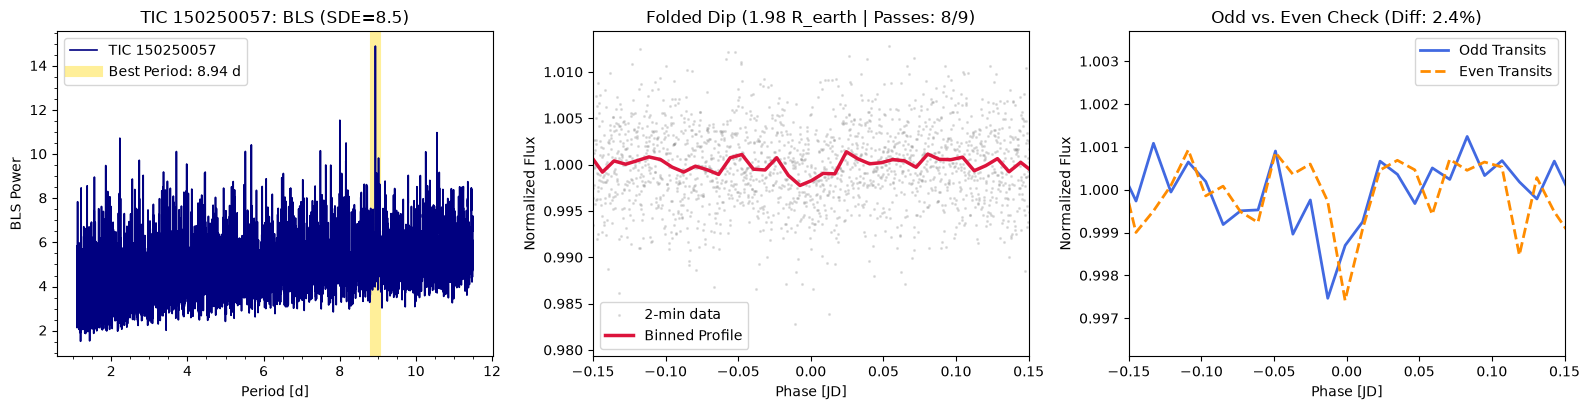


[2/14] === TIC 176954932 | PASS: Coherent Candidate ===
SDE: 8.38 | Period: 11.2379 d | Passes Dipped: 5/5 | Dip SNR: 12.97 | Radius: 1.08 R_earth | TSM: 8.6


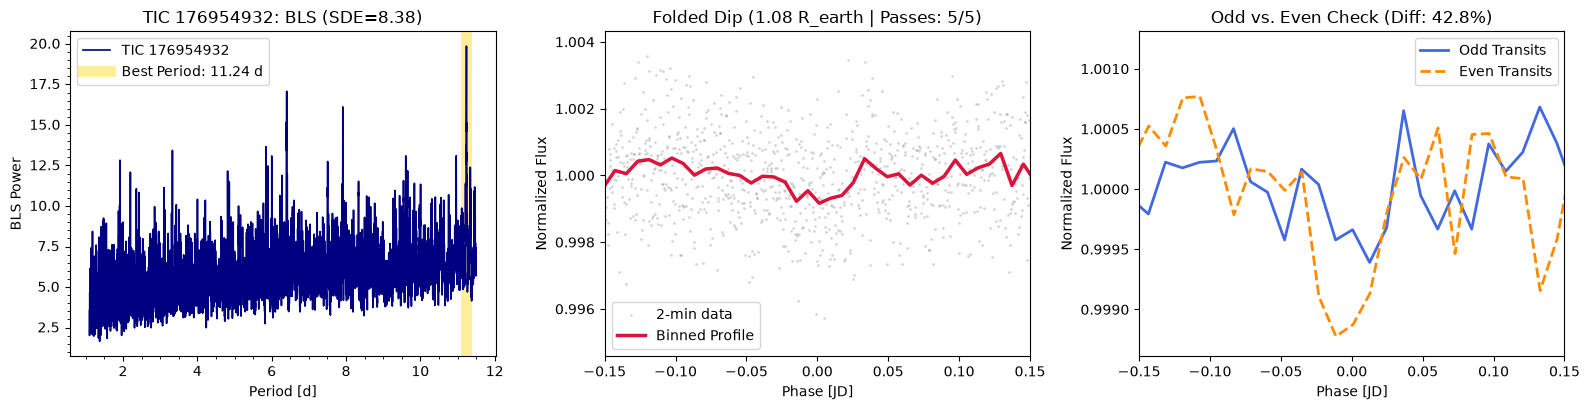


[3/14] === TIC 150438041 | PASS: Coherent Candidate ===
SDE: 7.28 | Period: 2.4251 d | Passes Dipped: 22/28 | Dip SNR: 2.97 | Radius: 1.12 R_earth | TSM: 4.4


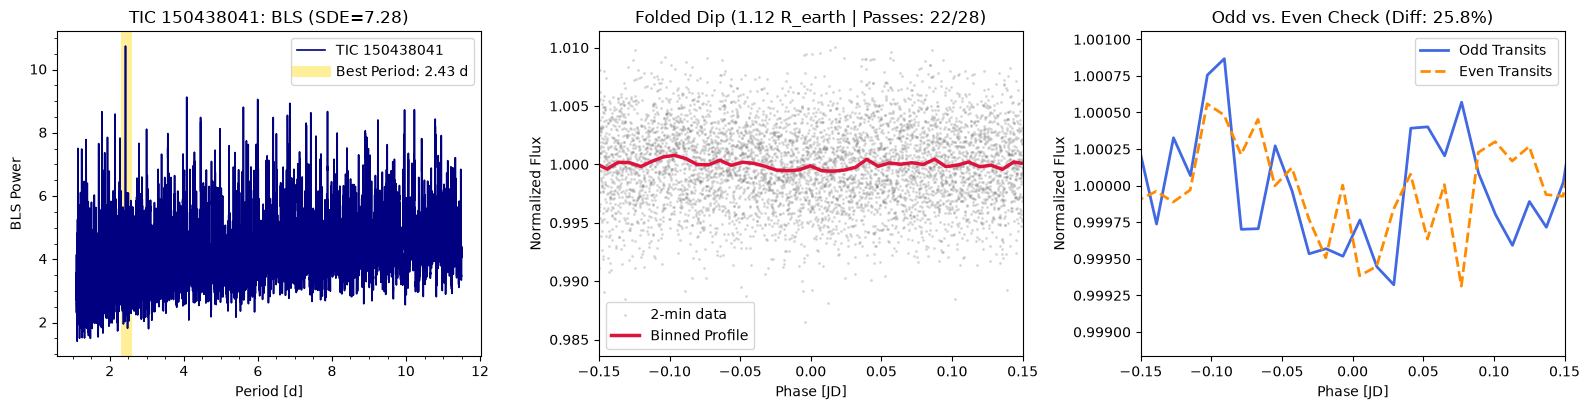


[4/14] === TIC 166970183 | PASS: Coherent Candidate ===
SDE: 7.19 | Period: 5.1314 d | Passes Dipped: 12/12 | Dip SNR: 6.0 | Radius: 1.01 R_earth | TSM: 5.2


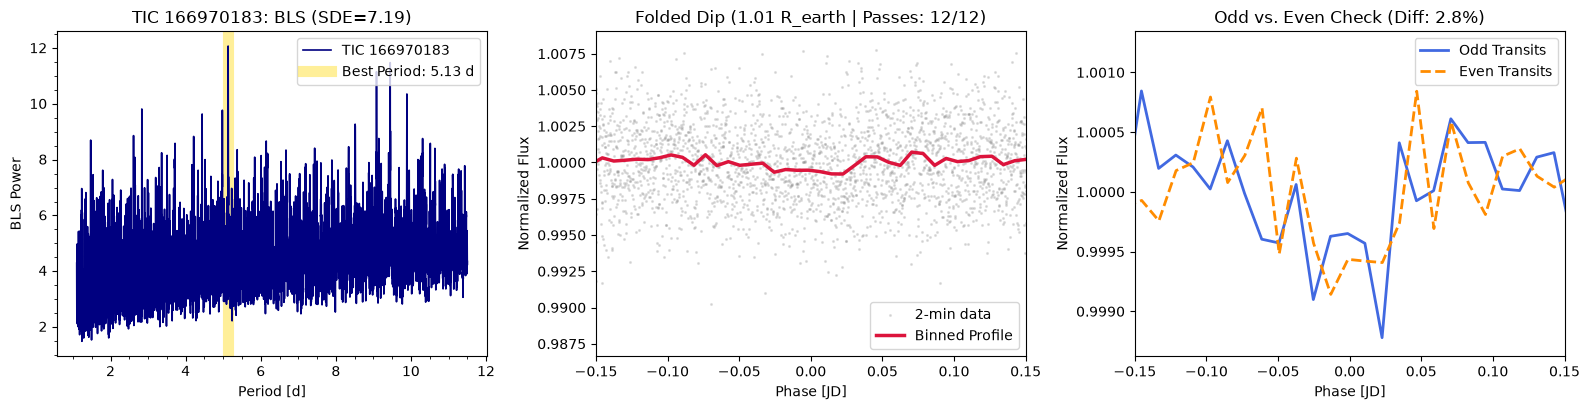


[5/14] === TIC 150064737 | PASS: Coherent Candidate ===
SDE: 7.05 | Period: 3.7221 d | Passes Dipped: 9/12 | Dip SNR: 3.79 | Radius: 1.71 R_earth | TSM: 27.6


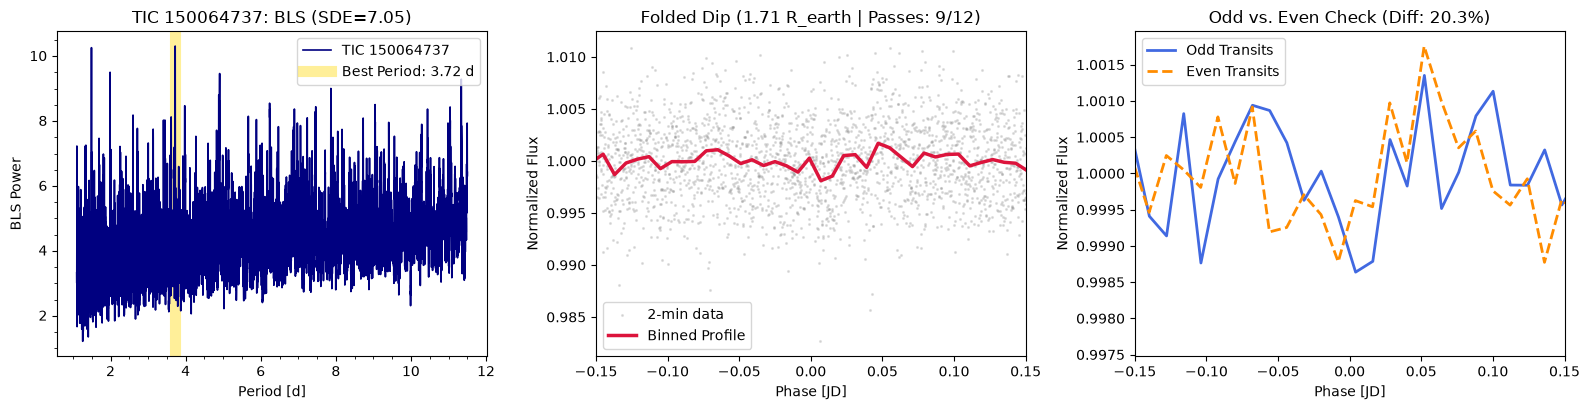


[6/14] === TIC 177236338 | PASS: Coherent Candidate ===
SDE: 6.6 | Period: 9.0194 d | Passes Dipped: 6/8 | Dip SNR: 8.01 | Radius: 1.2 R_earth | TSM: 4.6


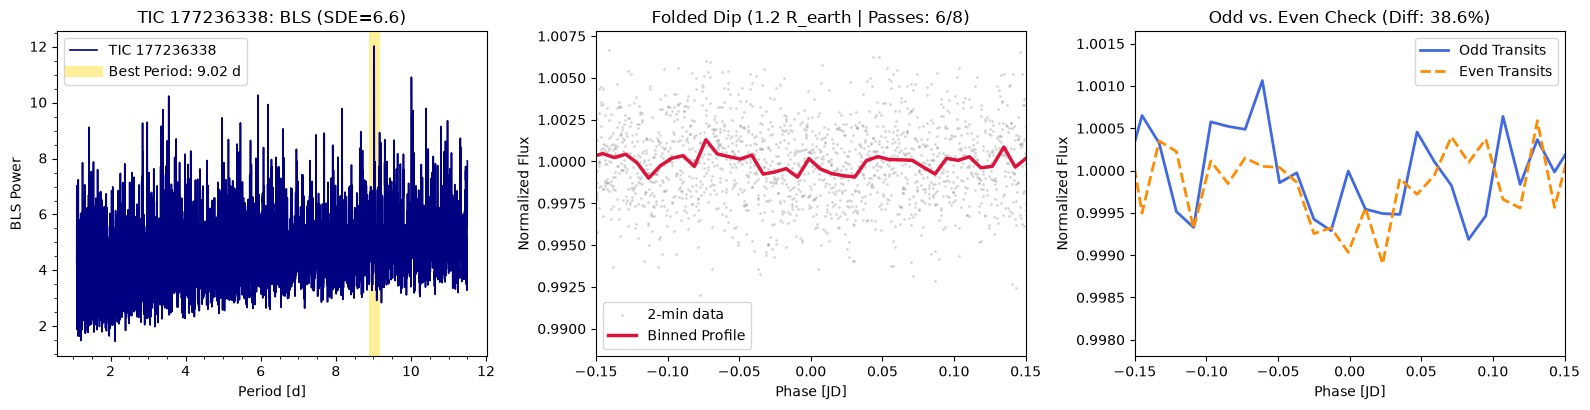


[7/14] === TIC 167308252 | Reject: Gap Glitch (54 transits) ===
SDE: 10.15 | Period: 1.1510 d | Passes Dipped: 36/54 | Dip SNR: 1.14 | Radius: 0.46 R_earth | TSM: 7.1


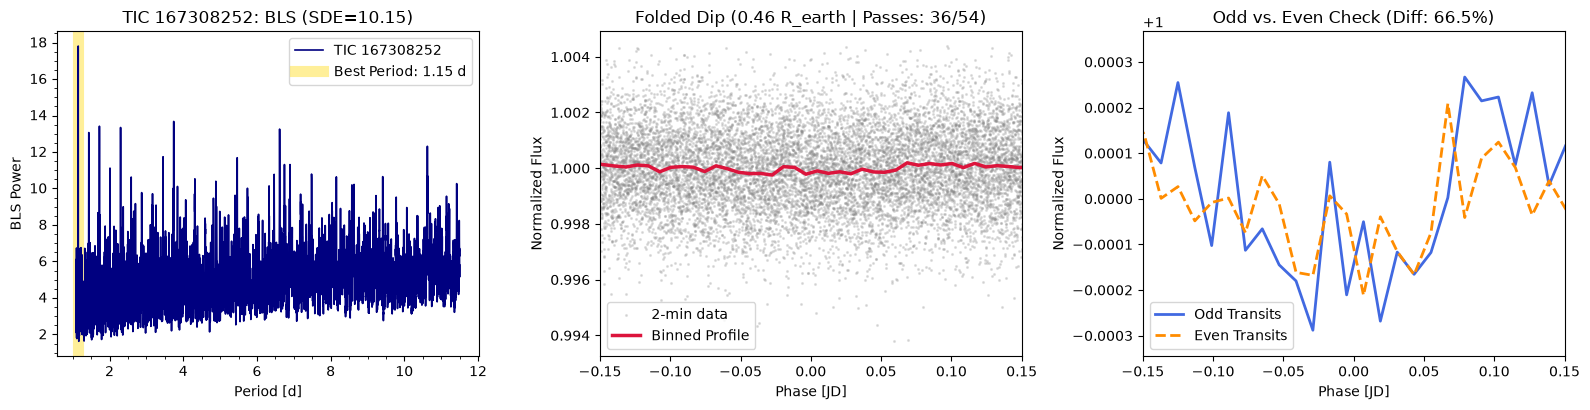


[8/14] === TIC 167338863 | Reject: Inconsistent Passes (8/11) ===
SDE: 7.59 | Period: 5.4684 d | Passes Dipped: 8/11 | Dip SNR: 5.58 | Radius: 1.14 R_earth | TSM: 5.4


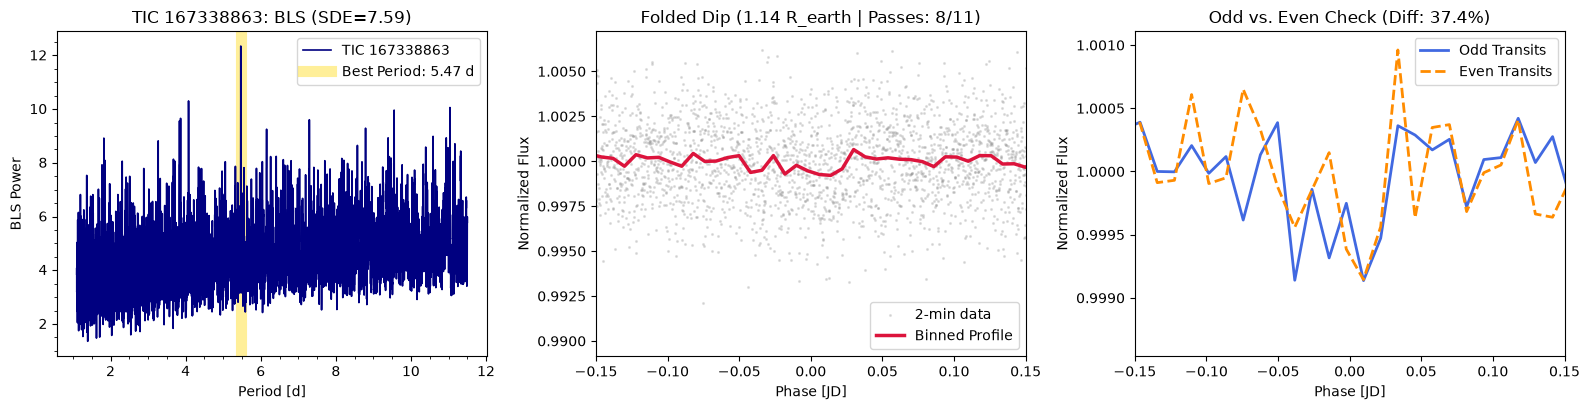


[9/14] === TIC 167422188 | Reject: Inconsistent Passes (22/36) ===
SDE: 7.46 | Period: 2.6196 d | Passes Dipped: 22/36 | Dip SNR: 4.02 | Radius: 0.8 R_earth | TSM: 5.2


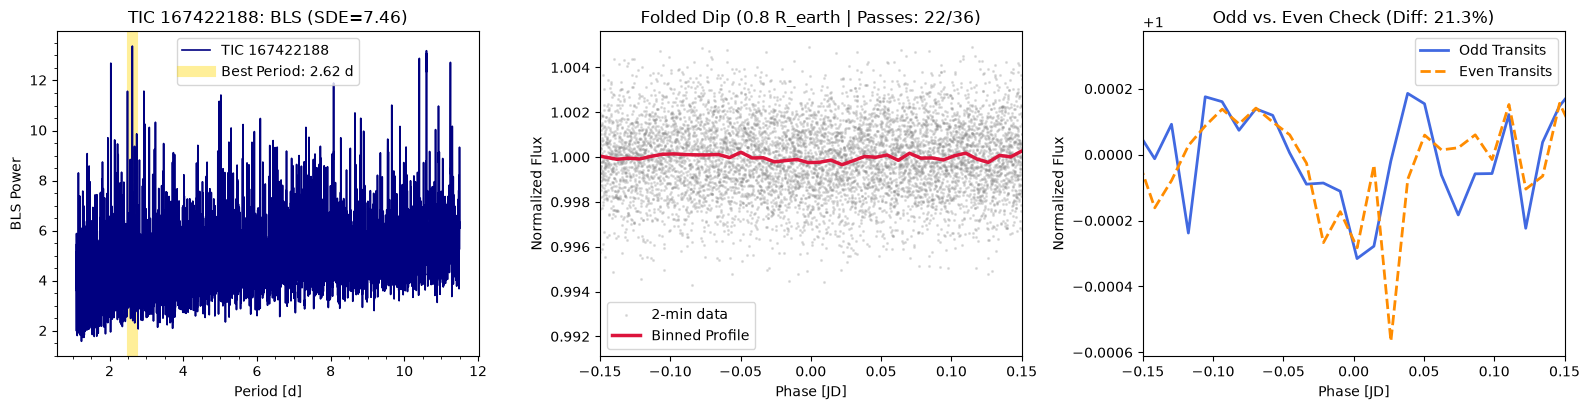


[10/14] === TIC 167417695 | Reject: Inconsistent Passes (23/35) ===
SDE: 7.05 | Period: 2.7818 d | Passes Dipped: 23/35 | Dip SNR: 2.58 | Radius: 0.83 R_earth | TSM: 5.2


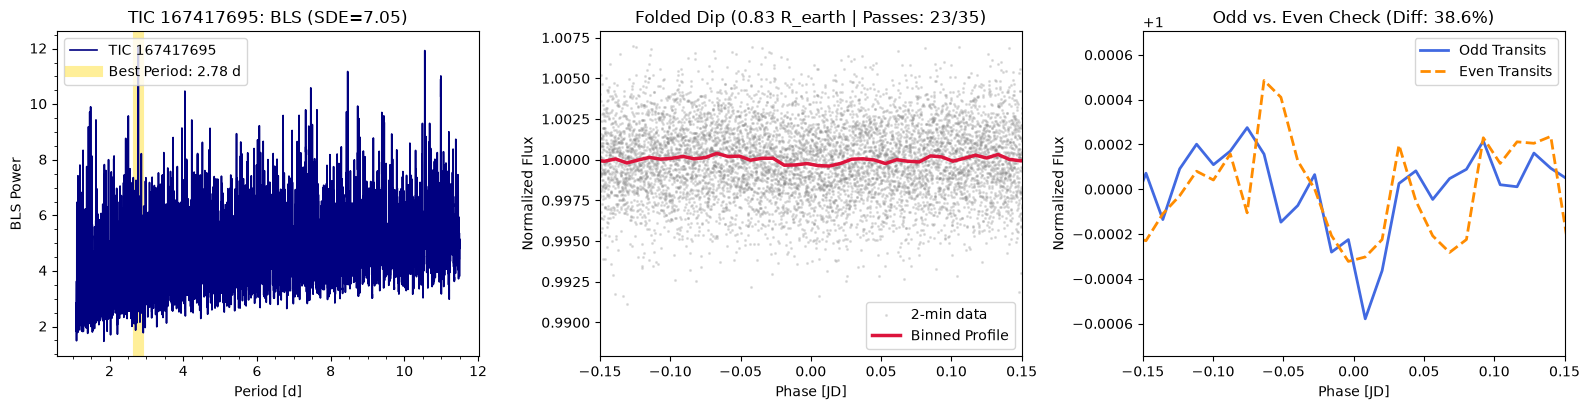


[11/14] === TIC 167721744 | Reject: Inconsistent Passes (17/24) ===
SDE: 6.91 | Period: 2.5780 d | Passes Dipped: 17/24 | Dip SNR: 4.63 | Radius: 0.78 R_earth | TSM: 6.2


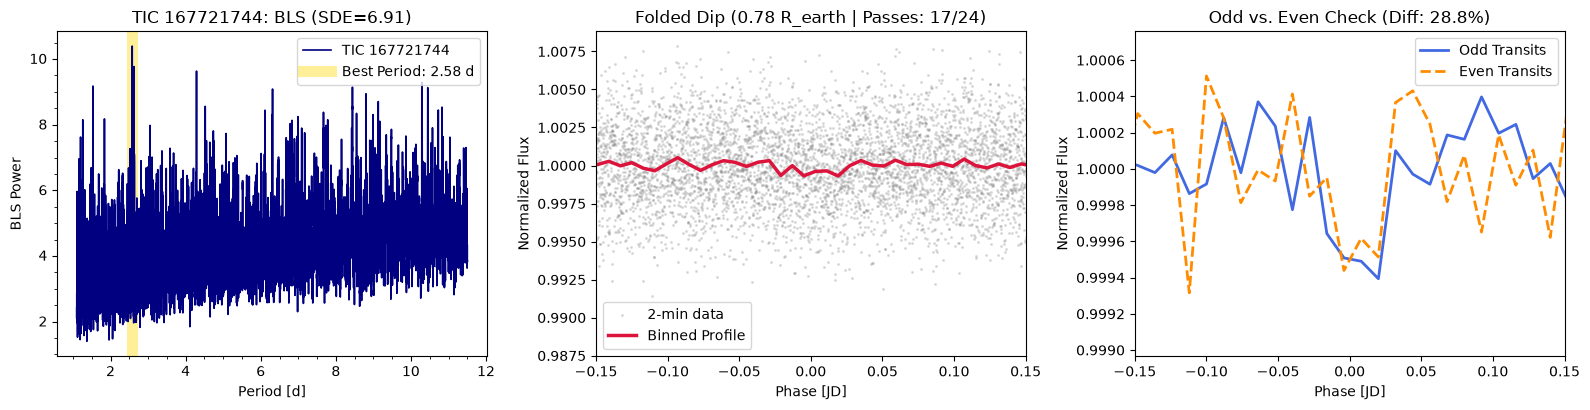


[12/14] === TIC 176955267 | Reject: Inconsistent Passes (11/17) ===
SDE: 6.88 | Period: 4.8028 d | Passes Dipped: 11/17 | Dip SNR: 7.87 | Radius: 0.78 R_earth | TSM: 7.4


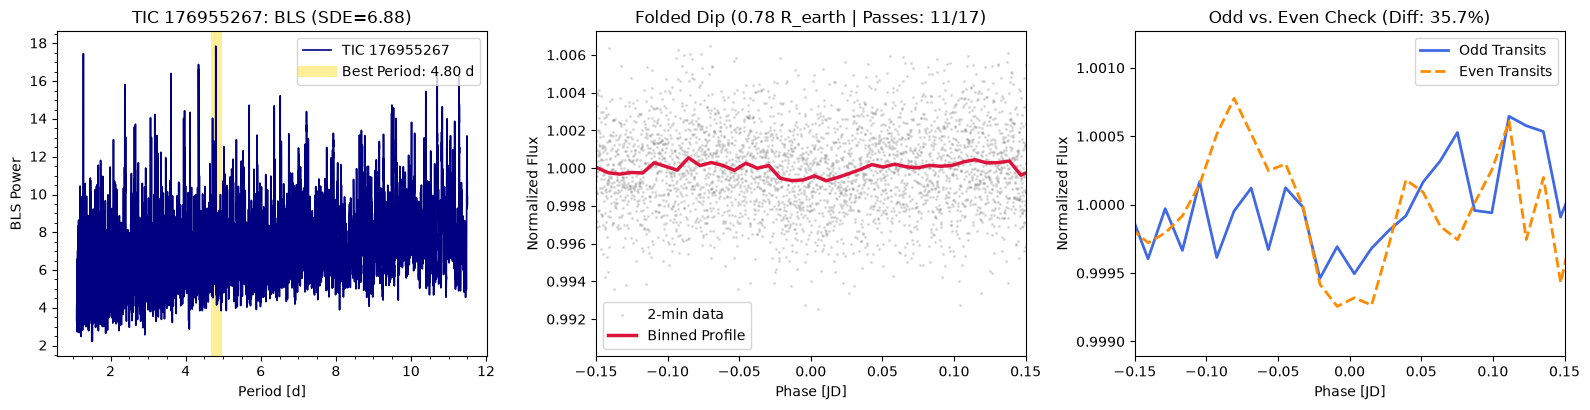


[13/14] === TIC 293347451 | Reject: Inconsistent Passes (12/18) ===
SDE: 6.85 | Period: 3.6753 d | Passes Dipped: 12/18 | Dip SNR: 4.34 | Radius: 1.25 R_earth | TSM: 2.9


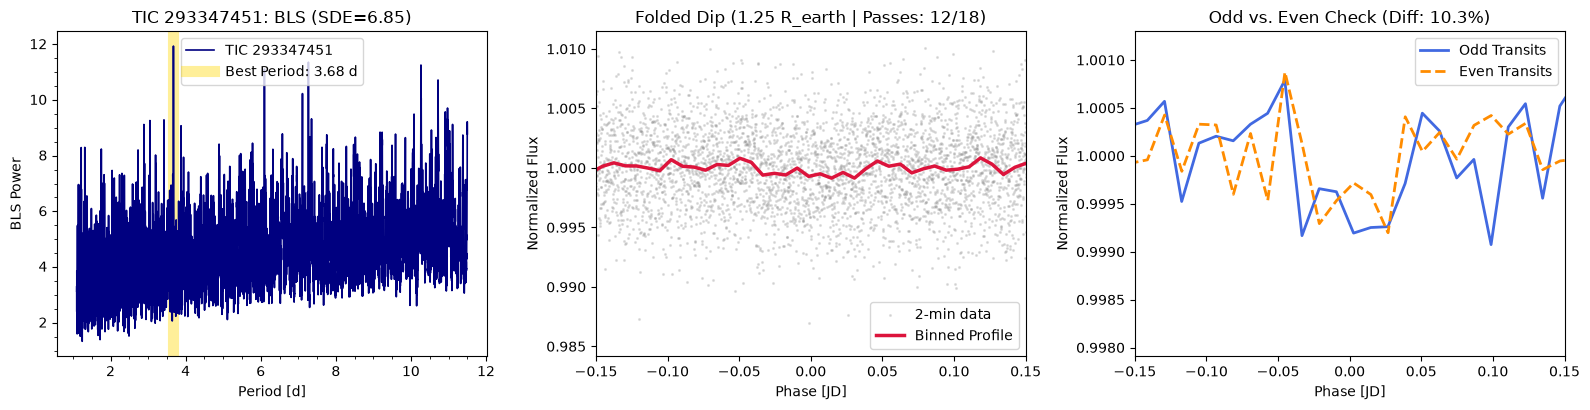


[14/14] === TIC 293223210 | Reject: Odd/Even Asymmetry ===
SDE: 6.65 | Period: 6.6084 d | Passes Dipped: 9/12 | Dip SNR: 8.3 | Radius: 1.52 R_earth | TSM: 22.5


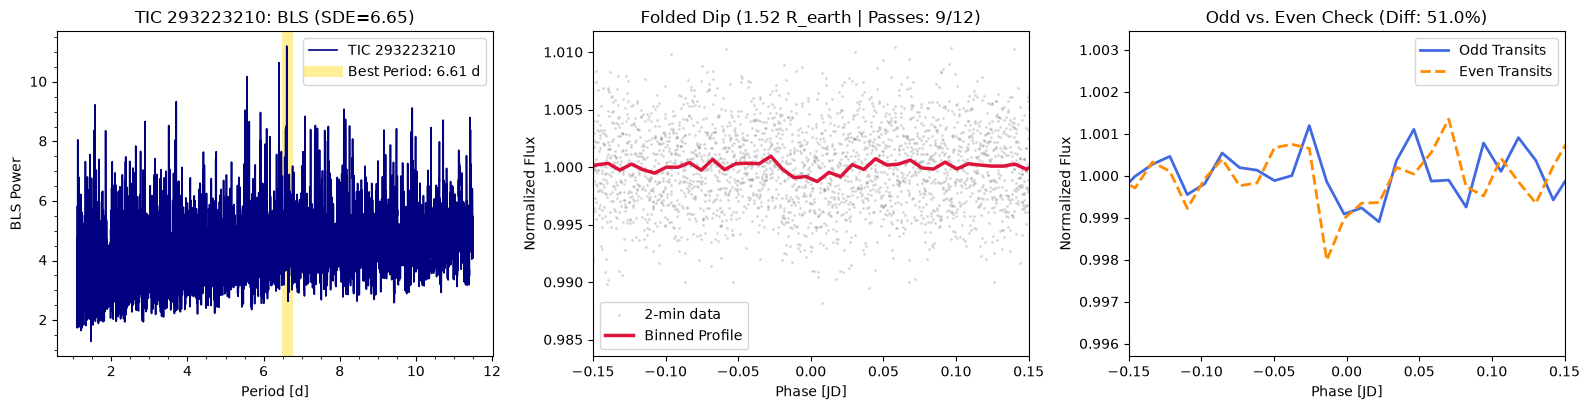

In [36]:
if len(high_sde_candidates) == 0:
    print("No candidates reached the SDE >= 6.4 threshold in this batch.")
else:
    # Sort so "PASS" candidates appear first, then by highest SDE
    sorted_candidates = sorted(
        high_sde_candidates.values(),
        key=lambda x: ("PASS" in x[0]["Vetting Verdict"], x[0]["SDE (Signal Strength)"]),
        reverse=True
    )
    
    for rank, (res, lc, bls) in enumerate(sorted_candidates, 1):
        p = res["Period (d)"]
        t0 = float(bls.transit_time_at_max_power.value)
        
        print(f"\n[{rank}/{len(sorted_candidates)}] === {res['TIC ID']} | {res['Vetting Verdict']} ===")
        print(
            f"SDE: {res['SDE (Signal Strength)']} | Period: {p:.4f} d | "
            f"Passes Dipped: {res['Transits']} | Dip SNR: {res['Dip SNR']} | "
            f"Radius: {res['Est. Radius (R_earth)']} R_earth | TSM: {res['JWST TSM']}"
        )
        
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.2))
        
        # BLS Periodogram
        bls.plot(ax=ax1, color="navy", lw=1.2, zorder=3)
        ax1.axvline(p, color="gold", lw=8, alpha=0.4, zorder=0, label=f"Best Period: {p:.2f} d")
        ax1.set_title(f"{res['TIC ID']}: BLS (SDE={res['SDE (Signal Strength)']})")
        ax1.legend()
        
        # Phase-Folded Transit Dip
        folded = lc.fold(period=p, epoch_time=t0)
        folded.scatter(ax=ax2, color="gray", alpha=0.2, s=6, label="2-min data")
        folded.bin(time_bin_size=0.008).plot(ax=ax2, color="crimson", lw=2.5, label="Binned Profile")
        ax2.set_xlim(-0.15, 0.15)
        ax2.set_title(f"Folded Dip ({res['Est. Radius (R_earth)']} R_earth | Passes: {res['Transits']})")
        ax2.legend()
        
        # Odd vs. Even Transit Overlay
        folded_odd = lc.fold(period=p * 2, epoch_time=t0)
        folded_even = lc.fold(period=p * 2, epoch_time=t0 + p)
        folded_odd.bin(time_bin_size=0.012).plot(ax=ax3, color="royalblue", lw=2, label="Odd Transits")
        folded_even.bin(time_bin_size=0.012).plot(ax=ax3, color="darkorange", lw=2, linestyle="--", label="Even Transits")
        ax3.set_xlim(-0.15, 0.15)
        ax3.set_title(f"Odd vs. Even Check (Diff: {res['Odd/Even Diff (%)']}%)")
        ax3.legend()
        
        plt.tight_layout()
        plt.show()

## Part 2: Individual Transit Pass Cheat Sheet (Cell 5)

Even if a signal looks clean when folded together in Cell 4, **a real orbiting planet cannot skip orbits**. Check the 4-column grid for **consistency across passes**:

1. **The Gold Band Rule (Pass Consistency $\ge 75\%$):**
   * **Pass:** In at least **3 out of every 4 boxes**, the crimson rolling-average line sags **below** the dashed navy `1.000` baseline inside the gold band.
   * **Reject (`BAD #1` below):** Multiple boxes stay flat at `1.000` or bump **upward** above the baseline inside the gold band.
2. **The Center vs. Shoulder Rule (Signal-to-Scatter):**
   * **Pass:** The dip inside the gold band is the deepest feature in the box, while the left/right shoulders hover near `1.000`.
   * **Reject (`BAD #2` below):** The red line bounces up and down in the white shoulders just as deeply as it does inside the gold band.
3. **The "Single Monster Glitch" Rule:**
   * **Pass:** Every dipping pass reaches roughly the **same ballpark depth** (e.g., all dropping to around `0.996–0.998`).
   * **Reject (`BAD #3` below):** One single box plunges way down (`0.985`) while the other boxes barely move—meaning a single camera glitch dragged the multi-sector average down.
4. **The Data Gap Rule:**
   * **Pass:** Gray 2-minute data dots are distributed continuously right through the center of the gold band.
   * **Reject (`BAD #4` below):** The gold band is empty white space (the predicted transit fell inside a spacecraft downlink gap).

![Individual Passes Vetting Guide](ref_passes_guide.png)


DEEP-DIVE PASS INSPECTION: TIC 167365380 (PASS: Coherent Candidate)
Period: 3.3279 d | Duration: 0.96 hrs | DipPasses: 16/20 | Dip SNR: 5.08 | Radius: 1.41 R_earth


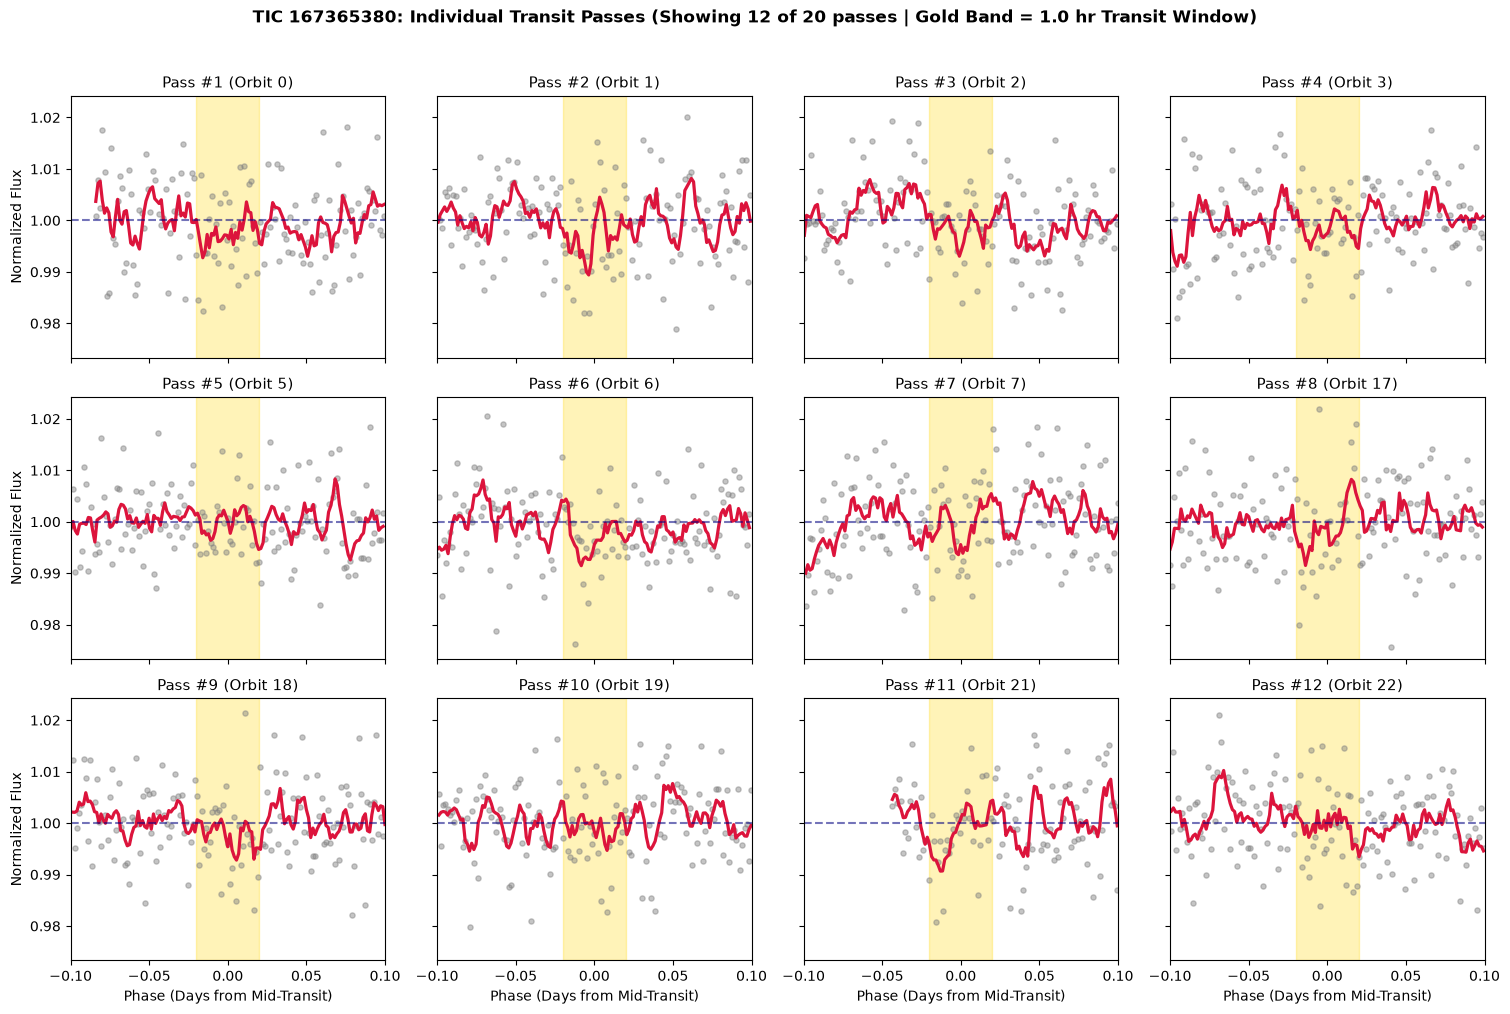

In [ ]:
import json
import math

# =====================================================================
# STREAMLINED CANDIDATE INSPECTOR SETTINGS
# - INSPECT_MODE: "ALL_PASSING" (auto-plots PASS stars) or "BY_RANK" (plots RANK_TO_INSPECT)
# - RANKS_TO_SAVE: List of rank numbers from Cell 4 that you want to save to disk
#                  Keep [] to save nothing, or set [1] or [1, 3] to save only those specific stars.
# =====================================================================
INSPECT_MODE = "ALL_PASSING"   # Options: "ALL_PASSING" or "BY_RANK"
RANK_TO_INSPECT = 1            # Used if INSPECT_MODE == "BY_RANK" (or if 0 candidates passed)
MAX_PASSES_TO_SHOW = 12        # Wraps cleanly into rows of 4
RANKS_TO_SAVE = []             # Example: [1] saves only Rank #1; [2, 4] saves Ranks #2 and #4

sorted_candidates = sorted(
    high_sde_candidates.values(),
    key=lambda x: ("PASS" in x[0]["Vetting Verdict"], x[0]["SDE (Signal Strength)"]),
    reverse=True
)

# Keep track of each candidate's official Rank # (1, 2, 3...) from Cell 4
ranked_tuples = [(rank, c[0], c[1], c[2]) for rank, c in enumerate(sorted_candidates, 1)]

if INSPECT_MODE == "ALL_PASSING":
    targets_to_plot = [item for item in ranked_tuples if "PASS" in item[1]["Vetting Verdict"]]
    if len(targets_to_plot) == 0 and len(ranked_tuples) > 0:
        fallback_idx = min(RANK_TO_INSPECT - 1, len(ranked_tuples) - 1)
        print(f"No candidates passed all automated filters in this batch. Showing Rank #{ranked_tuples[fallback_idx][0]} instead:")
        targets_to_plot = [ranked_tuples[fallback_idx]]
else:
    target_idx = min(RANK_TO_INSPECT - 1, len(ranked_tuples) - 1)
    targets_to_plot = [ranked_tuples[target_idx]] if len(ranked_tuples) > 0 else []

for rank_num, cand_res, cand_lc, cand_bls in targets_to_plot:
    tic_id = cand_res["TIC ID"]
    safe_name = tic_id.replace(" ", "_")
    p = cand_res["Period (d)"]
    t0 = float(cand_bls.transit_time_at_max_power.value)
    dur = float(cand_bls.duration_at_max_power.value)
    
    x_zoom = max(min(dur * 2.5, 0.14), 0.08)
    
    print(f"\n=======================================================")
    print(f"[RANK #{rank_num}] DEEP-DIVE PASS INSPECTION: {tic_id} ({cand_res['Vetting Verdict']})")
    print(f"Period: {p:.4f} d | Duration: {dur*24:.2f} hrs | DipPasses: {cand_res['Transits']} | Dip SNR: {cand_res['Dip SNR']} | Radius: {cand_res['Est. Radius (R_earth)']} R_earth")
    print(f"=======================================================")
    
    t_arr = np.asarray(cand_lc.time.value, dtype=float)
    f_arr = np.asarray(cand_lc.flux.value, dtype=float)
    phase_days = (t_arr - t0 + 0.5 * p) % p - 0.5 * p
    in_window = np.abs(phase_days) <= x_zoom
    orbit_nums = np.round((t_arr - t0) / p).astype(int)
    
    all_orbits = np.unique(orbit_nums[np.abs(phase_days) <= (0.5 * dur)])
    valid_orbits = [orb for orb in all_orbits if np.sum((orbit_nums == orb) & (np.abs(phase_days) <= 0.5 * dur)) >= 3]
    
    orbits_to_show = valid_orbits[:MAX_PASSES_TO_SHOW]
    n_transits = len(orbits_to_show)
    
    if n_transits > 0:
        n_cols = min(4, n_transits)
        n_rows = math.ceil(n_transits / 4)
        
        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(3.8 * n_cols, 3.3 * n_rows),
            sharex=True, sharey=True,
            squeeze=False
        )
        axes_flat = axes.flatten()
        
        for idx, orb in enumerate(orbits_to_show):
            ax = axes_flat[idx]
            mask = (orbit_nums == orb) & in_window
            sort_idx = np.argsort(phase_days[mask])
            t_slice = phase_days[mask][sort_idx]
            f_slice = f_arr[mask][sort_idx]
            
            ax.scatter(t_slice, f_slice, color="gray", alpha=0.45, s=14)
            if len(f_slice) >= 5:
                smooth = pd.Series(f_slice).rolling(6, center=True, min_periods=3).mean()
                ax.plot(t_slice, smooth, color="crimson", lw=2.3)
                
            ax.axhline(1.0, color="navy", linestyle="--", alpha=0.55)
            ax.axvspan(-0.5 * dur, 0.5 * dur, color="gold", alpha=0.28, zorder=0)
            ax.set_xlim(-x_zoom, x_zoom)
            ax.set_title(f"Pass #{idx+1} (Orbit {orb})", fontsize=10.5)
            
            if idx >= (n_rows - 1) * n_cols:
                ax.set_xlabel("Phase (Days from Mid-Transit)")
            if idx % n_cols == 0:
                ax.set_ylabel("Normalized Flux")
                
        for unused_idx in range(n_transits, len(axes_flat)):
            axes_flat[unused_idx].set_visible(False)
            
        plt.suptitle(
            f"[Rank #{rank_num}] {tic_id}: Individual Transit Passes (Showing {n_transits} of {len(valid_orbits)} passes | Gold Band = {dur*24:.1f} hr Window)",
            y=1.02, fontsize=12.5, fontweight="bold"
        )
        plt.tight_layout()
        
        # Save ONLY if this candidate's rank_num is in RANKS_TO_SAVE
        if rank_num in RANKS_TO_SAVE:
            cand_lc.to_pandas().to_csv(f"candidate_{safe_name}_lightcurve.csv", index=False)
            with open(f"candidate_{safe_name}_summary.json", "w") as f:
                json.dump(cand_res, f, indent=4)
            plt.savefig(f"candidate_{safe_name}_vetting.png", dpi=150, bbox_inches="tight")
            print(f"  -> SAVED Rank #{rank_num} ({tic_id}) CSV, JSON, and PNG to disk")
            
        plt.show()